# LKM Modeli ve Küçük Eğitim Denemesi

Bu defter LKM, RTM/FBO ön eğitimi, PromEnc, KPT ve KMPT uygulamasını ve küçük denemenin gerçek çıktılarını açıklar. Deneme tek başlangıç ve sınırlı eğitim/doğrulama örneği kullanır. Bağımsız test verisi değerlendirilmez; bu sonuçlar ana bilimsel karşılaştırma değildir.

**Tarihsel sürüm kaydı.** Bu defter ilk uygulamanın çıktısını korur. Yöntem denetimi ve düzeltilmiş ana sonuçlar 08_Makale_Yontem_Denetimi_ve_Duzeltilmis_Deneyler.ipynb içindedir. Öğrenci takibi için 05–07 defterleri güncel ağırlıklarla yeniden çalıştırılmıştır.

In [1]:
from pathlib import Path
import json
import sys
import inspect
import subprocess
import re
import pandas as pd
from IPython.display import display, Image, Markdown, Code

ROOT = Path.cwd().resolve()
if not (ROOT / "src" / "kt_project").exists():
    ROOT = ROOT.parent
assert (ROOT / "src" / "kt_project").exists()
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
RUN = ROOT / "outputs" / "pilot" / "lkm_128_device_batches"

## Küçük denemeyi çalıştırma veya kaydını açma

Tamamlanmış deneme varsa ağırlıklar ve çıktılar yeniden kullanılır. Yeni kurulumda yalnızca pilot ayarlarıyla küçük deneme çalışır; ana deney otomatik başlatılmaz.

In [2]:
if not (RUN / "results.json").exists():
    completed = subprocess.run([
        sys.executable, str(ROOT / "scripts" / "run_experiment.py"),
        "--config", "configs/pilot.json", "--output", str(RUN)
    ], cwd=ROOT, check=True)
status = json.loads((RUN / "status.json").read_text(encoding="utf-8"))
assert status["status"] == "complete"
results = json.loads((RUN / "results.json").read_text(encoding="utf-8"))
settings = json.loads((RUN / "config.json").read_text(encoding="utf-8"))
assert results["test_evaluated"] is False
assert all(row["test"] is None for row in results["runs"])
display(pd.DataFrame([{
    "Aygıt": results["gpu"], "Hassasiyet": results["precision"],
    "Eğitim öğrencisi üst sınırı": settings["train_student_limit"],
    "Uyarlama eğitim hedefi": results["runs"][0]["training_target_count"],
    "Doğrulama hedefi": results["runs"][0]["validation_target_count"],
    "En yüksek ayrılan GPU belleği MB": round(results["peak_allocated_gpu_mb"], 1),
}]))

,Aygıt,Hassasiyet,Eğitim öğrencisi üst sınırı,Uyarlama eğitim hedefi,Doğrulama hedefi,En yüksek ayrılan GPU belleği MB
0,NVIDIA GeForce RTX 4060,bfloat16,96,2048,512,437.5


## Model yapısı

LKM iki katmanlı, dört dikkat başlıklı ve 128 boyutlu bir Transformer kodlayıcısıdır. Soru, beceri, cevap, zorluk ve konum temsillerini kullanır. PromEnc bir katman ve sekiz öğrenilebilir prompt içerir. Üç yöntemde de LKM uyarlanır; deney saf PEFT karşılaştırması değildir.

In [3]:
from kt_project.models import LargeKnowledgeModel, KnowledgeTracer
display(pd.DataFrame([{
    "Yöntem": row["method"], "Toplam parametre": row["parameters"]["total"],
    "Eğitilen parametre": row["parameters"]["trainable"],
} for row in results["runs"]]))
display(Markdown((ROOT / "docs" / "model_yontemi.md").read_text(encoding="utf-8")))

,Yöntem,Toplam parametre,Eğitilen parametre
0,baseline,4836529,2634241
1,kpt,5021104,2818945
2,kmpt,5021104,5020975


# Bilgi Takibi Modeli ve Eğitim Yöntemi

Uygulama; LKM ön eğitimi, promptsuz uyarlama, KPT ve KMPT bileşenlerini içerir. İlk küçük deneme bu bileşenlerin çalışmasını ve veri güvenilirliğini doğrular. Bağımsız test verisindeki üç başlangıçlı ana karşılaştırma ayrı deney olarak yürütülecektir.

## Etkileşim temsili

Bir geçmiş olayı soru kimliği, bir veya daha fazla beceri, doğru veya yanlış cevap ve eğitimden hesaplanmış soru zorluğuyla temsil edilir. Soru, beceri ve cevap temsilleri ile zorluk ve konum temsilleri birleştirilir. Bir olay birden fazla beceri içeriyorsa geçerli beceri temsillerinin ortalaması kullanılır.

Soru için PAD, UNK ve MASK; beceri için PAD ve UNK ayrılmış kimliklerdir. Eğitimde görülmeyen soru veya becerinin temsili başlangıçta sıfırdır. Dolgu konumları dikkat hesabında anahtar olarak kullanılamaz.

## LKM ön eğitimi

Ön eğitim yalnızca eğitim öğrencilerinin kayıtlarını kullanır. Geçmişler en fazla 128 olaylık parçalara bölünür. En az iki olay içeren her pencere iki ardışık parçaya ayrılır; başına CLS ve parçalar arasına SEP eklenir.

RTM için olay konumlarının yaklaşık yüzde 15'i seçilir. Kısa bir dizide en az bir konum seçilir. Seçilen konumdaki soru ve cevap bileşenleri ayrı ayrı yüzde 80 olasılıkla maskelenir, yüzde 10 olasılıkla aynı dizideki başka bir gerçek konumdan alınır, yüzde 10 olasılıkla değiştirilmez. Kayıp yalnızca seçilen konumlarda hesaplanır. Beceri ve zorluk yardımcı bilgi olarak korunur.

FBO olumlu örneğinde iki parça aynı özgün pencereden gelir. Olumsuz örnekte ikinci parça farklı bir eğitim öğrencisinin penceresinden alınır. Olumlu ile olumsuz örnek oranı, yuvarlama farkı dışında 2:1'dir. Ön eğitimde iki yönlü dikkat kullanılır.

Toplam kayıp, maskeli soruların çok sınıflı çapraz entropisi, maskeli cevapların ikili çapraz entropisi ve FBO ikili çapraz entropisinin toplamıdır. Her bileşen kendi geçerli örnekleri üzerinde ortalanır. Üç kayıp ayrı kaydedilir; soru başlığının kaybı cevap tahmini BCE değeriyle aynı ölçü olarak yorumlanmaz.

## Üç uyarlama yöntemi

Her başlangıç için aynı ön eğitimli LKM ağırlıkları üç yönteme kopyalanır. Ortak başlangıç, ağırlıkların içerik özetiyle doğrulanır.

| Yöntem | Tahmin yapısı | Eğitim hedefi |
|---|---|---|
| Promptsuz uyarlama | Maskeli cevap içeren hedef etkileşim ve yeni sınıflandırma başlığı | Sonraki cevabın ikili kaybı |
| KPT | Öğrenilebilir promptlar ve bilgi kavramıyla yönlendirilmiş şablon; ön eğitimli cevap başlığı | Sonraki cevabın ikili kaybı |
| KMPT | KPT ile aynı cevap şablonu ve yardımcı soru şablonu | Örneklerin yaklaşık yüzde 80'inde cevap, yüzde 20'sinde soru tahmini |

Üç yöntemde de LKM uyarlanır. KPT ve KMPT'de PromEnc ile soft promptlar da eğitilir. FBO başlığı uyarlamada dondurulur. Soru başlığı yalnızca KMPT'de; ön eğitimli cevap başlığı KPT ve KMPT'de güncellenir. Promptsuz yöntemde yeni sınıflandırma başlığı eğitilir.

Bu deney saf parametre verimli prompt eğitimi karşılaştırması değildir. KPT ve KMPT'nin farkları şablon, ek kodlayıcı, başlık kullanımı ve hedeflerle birlikte değerlendirilir. Eğitilen parametre sayıları ayrıca raporlanır; farklar yalnızca soft promptlara atfedilmez.

## Tahmin sırasında bilgi sınırı

Bir tahmin örneği hedef olaydan önceki en fazla 128 etkileşimi içerir. Hedef cevabı etiket olarak saklanır; tahmin girdisine alınmaz. Sonraki cevabı tahmin eden LKM dikkat maskesi nedenseldir.

KPT şablonunun sırası soft promptlar, hedef soru, beceri ve maskeli cevaptır. KMPT yardımcı şablonunda bilinen cevap ve beceri önce, maskeli soru sonradır. Maskeli bileşenin sonda bulunması, nedensel LKM'nin promptları görebilmesini sağlar. Yardımcı şablon yalnızca KMPT eğitimi sırasında kullanılabilir; değerlendirme yolu her zaman cevap maskeli şablondur.

PromEnc yalnızca bu şablonun bileşenleri üzerinde iki yönlü çalışır. Tahminde şablonun içinde hedefin gerçek cevabı veya sonraki olaylar bulunmaz. LKM'nin geçmiş etkileşimleri nedensel kalır. Bu düzen, makaledeki şablon sırası ve tahminde PromEnc dikkatini değiştirme tarifinin birebir kopyası değildir; fark açıkça belirtilir.

Konum kimlikleri öğrencinin gerçek geçmiş uzunluğuna göre atanır. Aynı öğrenci başka uzunlukta geçmişlerle aynı toplu girdiye girdiğinde dolgu sayısının tahmini değiştirmemesi denetlenir.

## Kapasite ve donanım

Prototip LKM iki Transformer katmanı, dört dikkat başlığı ve 128 boyutlu temsil kullanır. PromEnc bir katman ve sekiz öğrenilebilir prompt içerir. Bu kapasite makalenin A100 üzerinde kullandığı modelden küçüktür; sonuçlar birebir makale yeniden üretimi olarak sunulmaz.

CUDA üzerinde destek varsa bfloat16 karma hassasiyet kullanılır; model ağırlıkları standart hassasiyette kalır. Küçük deneme 128'lik toplu girdilerle çalışmıştır. Yalnızca eğitim girdileriyle yapılan hız ve bellek ölçümünde ana deney için 512'lik toplu girdi seçilmiştir. 1024'teki küçük hız kazanımı yaklaşık iki kat bellek gerektirdiğinden 512 tercih edilir.

## Seçim ve değerlendirme

En iyi uyarlama ağırlıkları doğrulama BCE değerinin en düşük olduğu dönemden seçilir. AUC ve doğruluk o aynı dönemin değerleridir; her ölçü için farklı dönem seçilmez. KMPT'nin yardımcı soru kaybı ortak model karşılaştırma ölçüsü değildir.

Ana deney başlangıçları 17, 42 ve 2026'dır. Öğrenci ayrımı sabit kalır. Ayarlar ana deneyde test sonuçlarına göre değiştirilmez. Her yöntemin seçilmiş ağırlıkları bağımsız testte değerlendirilir; eğitimde görülen soru alt grubunun sonucu da ayrıca saklanır.

## Kaynaklar

- Zhu, Qiu ve Zhou, [Prompt tuning for improving knowledge tracing in intelligent tutoring](https://link.springer.com/article/10.1007/s10618-026-01208-9), özellikle yöntem bölümleri 3.2 ile 3.5. Kullanıcının sağladığı tam metin esas alınmıştır.
- [PyTorch TransformerEncoder](https://docs.pytorch.org/docs/2.14/generated/torch.nn.TransformerEncoder.html): katmanların ayrı başlatılması ve dikkat maskeleri.
- [PyTorch karma hassasiyet](https://docs.pytorch.org/docs/2.14/amp.html): CUDA autocast ve gerektiğinde gradyan ölçekleme.


## RTM ve FBO kayıplarını hesaplayan kod

Maskeli soru ve cevaplar ayrı başlıklarla geri bulunur. CLS konumu iki parçanın doğru ardışıklığını tahmin eder. Kayıplar birlikte optimize edilir; her birinin değeri ayrı kaydedilir.

def pretraining_loss(self, batch):
        embeddings = self.interaction_embeddings(batch["question"], batch["skills"],
                                                 batch["response"], batch["difficulty"])
        embeddings = torch.where(batch["special"].gt(0).unsqueeze(-1),
                                 self.special_embedding(batch["special"]), embeddings)
        hidden = self.encode(embeddings, batch["padding"], causal=False)
        question_mask = batch["question_labels"].ne(-100)
        response_mask = batch["response_labels"].ne(-100)
        # Büyük soru sözlüğü için yalnızca maskeli konumların logits'leri üretilir.
        question_loss = F.cross_entropy(self.question_head(hidden[question_mask]),
                                       batch["question_labels"][question_mask])
        response_loss = F.binary_cross_entropy_with_logits(
            self.response_head(hidden[response_mask]).squeeze(-1),
            batch["response_labels"][response_mask].float())
        order_loss = F.binary_cross_entropy_with_logits(
            self.order_head(hidden[:, 0]).squeeze(-1), batch["fbo_label"])
        loss = question_loss + response_loss + order_loss
        return loss, {"question_loss": question_loss.detach(),
                      "response_loss": response_loss.detach(), "order_loss": order_loss.detach()}

,epoch,samples,loss,question_loss,response_loss,order_loss,seconds
0,1,188,11.153851,9.756578,0.682563,0.714710,0.666264
1,2,188,10.949043,9.720711,0.588826,0.639507,0.082487
2,3,188,10.906693,9.667870,0.598026,0.640797,0.098802


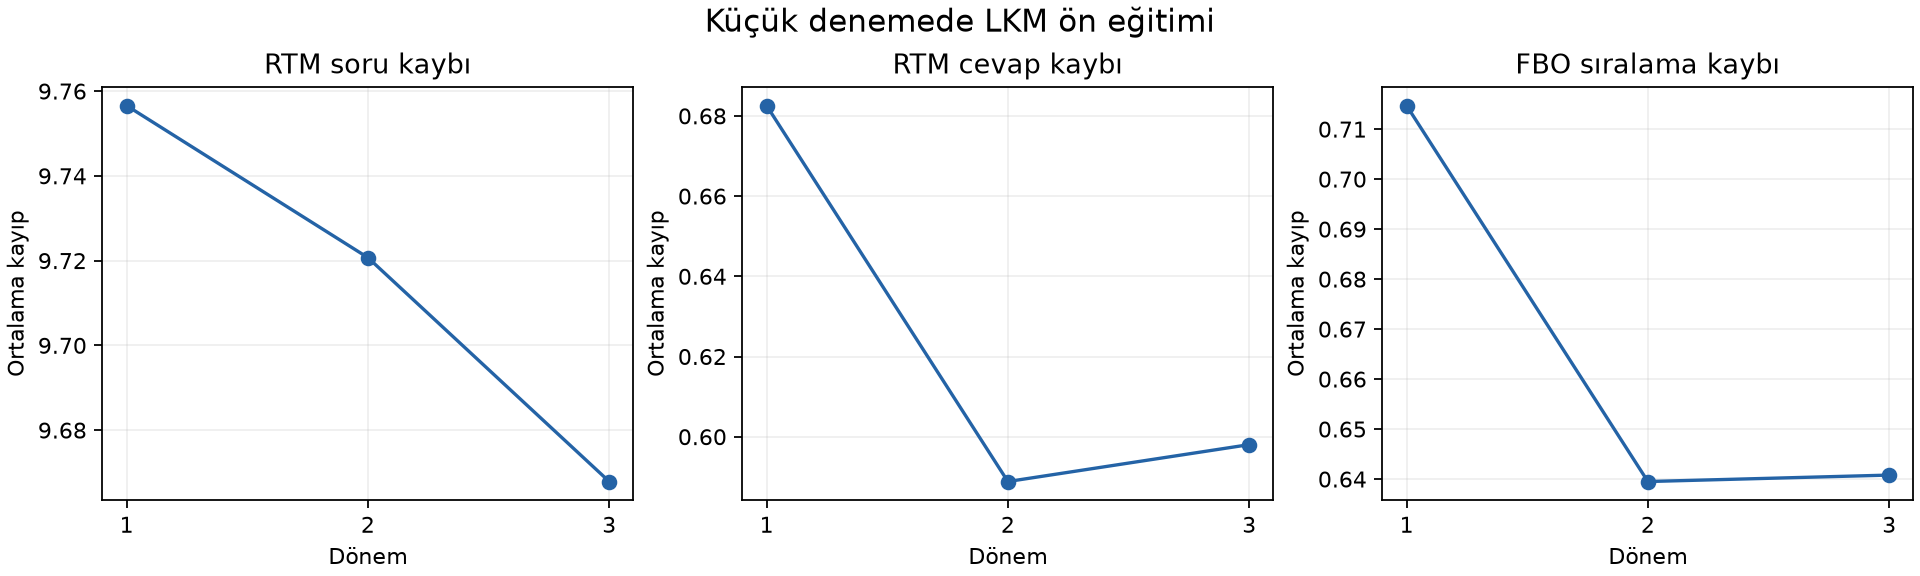

In [4]:
display(Code(inspect.getsource(LargeKnowledgeModel.pretraining_loss), language="python"))
history = json.loads((RUN / "seed_17" / "pretraining_history.json").read_text(encoding="utf-8"))
display(pd.DataFrame(history))
display(Image(filename=str(ROOT / "outputs" / "figures" / "pilot_pretraining.png")))

## Hedef cevabın gizlenmesi ve promptların görünürlüğü

Normal tahmin yolunda label, hedef cevabın embedding girdisine alınmaz. Soft promptlar maskeli hedef bileşenden önce yerleştirilir; böylece nedensel LKM bunları görebilir. Yardımcı soru tahmini yalnızca KMPT eğitimi sırasında gerçek hedef cevabını kullanabilir.

In [5]:
display(Code(inspect.getsource(KnowledgeTracer.encode_prediction), language="python"))

def encode_prediction(self, batch, auxiliary=False):
        question, skills, difficulty = (batch[key] for key in
                                        ("target_question", "target_skills", "target_difficulty"))
        history = self.lkm.interaction_embeddings(
            batch["history_question"], batch["history_skills"],
            batch["history_response"], batch["history_difficulty"])
        batch_size, history_width = history.shape[:2]
        if auxiliary:
            if self.method != "kmpt" or not self.training:
                raise ValueError("Yardımcı soru tahmini yalnızca KMPT eğitimi içindir.")
            question = torch.full_like(question, QUESTION_MASK)
            response = batch["label"].long()
        else:
            # label alanı tahmin girdisine hiçbir yoldan alınmaz.
            response = torch.full_like(question, RESPONSE_MASK)
        if self.method == "baseline":
            template = self.lkm.interaction_embeddings(question, skills, response, difficulty).unsqueeze(1)
        else:
            q = self.lkm.question_embedding(question) + self.lkm.difficulty_embedding(difficulty.unsqueeze(-1))
            c = self.lkm.concept_embeddings(skills)
            r = self.lkm.response_embedding(response)
            template = self.prompt_encoder(q, c, r, auxiliary=auxiliary)
        cls = self.lkm.special_embedding.weight[1].expand(batch_size, 1, -1)
        embeddings = torch.cat([cls, history, template], dim=1)
        padding = torch.cat([torch.zeros(batch_size, 1, device=history.device, dtype=torch.bool),
                             batch["history_padding"],
                             torch.zeros(batch_size, template.shape[1], device=history.device, dtype=torch.bool)], dim=1)
        lengths = (~batch["history_padding"]).sum(dim=1)
        # Konumlar dolgu sayısından bağımsız; aynı öğrenci farklı bir grupta aynı tahmini alır.
        positions = torch.cat([
            torch.zeros(batch_size, 1, device=history.device, dtype=torch.long),
            torch.arange(1, history_width+1, device=history.device).expand(batch_size, -1),
            lengths[:, None] + torch.arange(1, template.shape[1]+1, device=history.device)], dim=1)
        return self.lkm.encode(embeddings, padding, positions, causal=True)[:, -1]

## Ortak başlangıç ve doğrulama sonuçları

Üç yöntem aynı LKM ağırlığından başlar. En iyi dönem doğrulama BCE değerine göre seçilir; AUC ve doğruluk o aynı dönemin değerleridir. Birden fazla bileşen değiştiği için farklar yalnızca soft promptların etkisi olarak yorumlanmaz.

,Yöntem,BCE ile seçilen dönem,Başlangıç doğrulama BCE,Seçilen doğrulama BCE,Seçilen doğrulama AUC,Seçilen doğrulama doğruluğu
0,baseline,2,0.6943,0.6125,0.7425,0.6934
1,kpt,2,0.7283,0.6199,0.7247,0.6582
2,kmpt,1,0.7283,0.6527,0.6542,0.6191


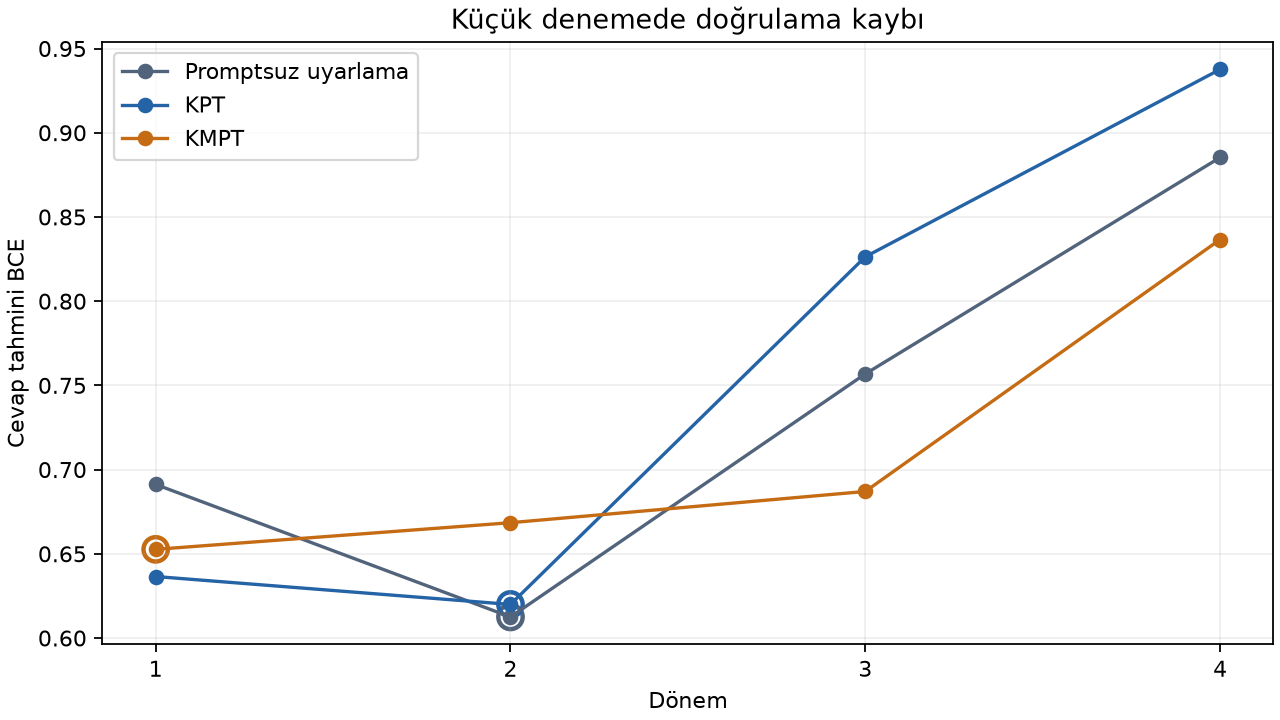

In [6]:
assert len({row["initial_lkm_sha256"] for row in results["runs"]}) == 1
display(pd.DataFrame([{
    "Yöntem": row["method"], "BCE ile seçilen dönem": row["best_epoch"],
    "Başlangıç doğrulama BCE": row["initial_validation"]["bce"],
    "Seçilen doğrulama BCE": row["validation"]["bce"],
    "Seçilen doğrulama AUC": row["validation"]["auc"],
    "Seçilen doğrulama doğruluğu": row["validation"]["accuracy"],
} for row in results["runs"]]).round(4))
display(Image(filename=str(ROOT / "outputs" / "figures" / "pilot_validation_bce.png")))

## Kayıtlı ağırlıkları yeniden yükleyerek denetleme

Ağırlıklar yeniden yüklenir ve doğrulama ölçülerinin yeniden üretildiği kontrol edilir. Hedef etiket değiştirildiğinde tahminin değişmediği, KPT ve KMPT promptlarının CUDA üzerinde gradyan aldığı doğrulanır.

In [7]:
audited = subprocess.run([sys.executable, str(ROOT / "scripts" / "audit_pilot.py")],
                         cwd=ROOT, capture_output=True, text=True, encoding="utf-8", check=True)
audit = json.loads(audited.stdout)
assert audit["common_pretrained_state_verified"] and audit["test_not_evaluated"]
display(pd.DataFrame(audit["checks"]))

,method,checkpoint_reloaded,validation_metrics_reproduced,target_label_invariance,prompt_gradient_norm
0,baseline,True,True,True,NaN
1,kpt,True,True,True,0.061745
2,kmpt,True,True,True,0.020059


## Veri ve model güvenilirliği testleri

Testler öğrenci ayrımı, zorluğun eğitimden hesaplanması, hedef cevabın gizlenmesi, nedensellik, dolgu bağımsızlığı ve promptların gerçekten güncellenmesini denetler. Geçerli test çıktısı kaydedilir.

In [8]:
checked = subprocess.run([sys.executable, "-m", "unittest", "discover", "-s", "tests", "-v"],
                         cwd=ROOT, capture_output=True, text=True, encoding="utf-8")
transcript = checked.stdout + checked.stderr
print(transcript)
assert checked.returncode == 0, "Güvenilirlik kontrolü başarısız."
(ROOT / "outputs" / "validation" / "model_test_output.txt").write_text(transcript, encoding="utf-8")
count = int(re.search(r"Ran (\d+) tests", transcript).group(1))
print("Başarılı kontrol sayısı:", count)

test_multiple_skills_are_one_event_and_conflicts_are_excluded (test_data_preparation.PreparationTests.test_multiple_skills_are_one_event_and_conflicts_are_excluded) ... ok
test_test_answers_do_not_change_training_difficulty_or_references (test_data_preparation.PreparationTests.test_test_answers_do_not_change_training_difficulty_or_references) ... ok
test_different_accounts_never_share_runtime_in_the_same_profile (test_jupyter_launcher.LauncherTests.test_different_accounts_never_share_runtime_in_the_same_profile) ... ok
test_launch_remains_local_with_the_original_notebook (test_jupyter_launcher.LauncherTests.test_launch_remains_local_with_the_original_notebook) ... ok
test_old_project_runtime_is_overridden_and_project_kernel_is_preserved (test_jupyter_launcher.LauncherTests.test_old_project_runtime_is_overridden_and_project_kernel_is_preserved) ... ok
test_auxiliary_answer_is_only_allowed_during_kmpt_training (test_model_integrity.ModelIntegrityTests.test_auxiliary_answer_is_only_allowe

## Ana deney hazırlığı

Ana deney ayarları configs/main.json dosyasında ayrı tutulur. Üç başlangıç, tam eğitim ve doğrulama öğrencileri, ortak ön eğitim ve ayrılmış test değerlendirmesi kullanılacaktır. Küçük denemedeki yöntem sıralaması veya sayılar nihai sonuç olarak aktarılmaz. Çalışan modelin hazırlanması ile ana deneyin tamamlanması ayrı aşamalardır.